# Capacity Factor Predictions of Hydro Power Plants

### Define Hydropower Plant Parameters

To estimate daily energy production and capacity factors, this section defines key **technical metadata** for each plant.

Each hydropower site is assigned:
- **Name**
- **Location Coordinates**
- **Type** (Storage/Run-of-River)
- **Commissioning Year**
- **Catchment area** (in m²)
- **Runoff coefficient**
- **Gross head** (in m)
- **Turbine-generator efficiency**
- **Installed capacity** (in MW)

In [1]:
import pandas as pd
import folium

# Define full hydropower plant data including technical parameters
hydropower_plants = pd.DataFrame([
    {
        "Name": "Bumbuna I",
        "Capacity_MW": 50,
        "Latitude": 9.0568,
        "Longitude": -11.7361,
        "Type": "Storage",
        "Commissioning": "Existing",
        "Catchment_Area_m2": 3.92e9,       # 3920 km²
        "Head_m": 100,
        "Efficiency": 0.90,
        "Runoff_Coefficient": 0.75
    },
    {
        "Name": "Bumbuna II",
        "Capacity_MW": 143,
        "Latitude": 9.071944,
        "Longitude": -11.722500,
        "Type": "Storage",
        "Commissioning": "2026",
        "Catchment_Area_m2": 3.92e9,       # Same river section assumed
        "Head_m": 147,
        "Efficiency": 0.90,
        "Runoff_Coefficient": 0.75
    },
    {
        "Name": "Bekongor",
        "Capacity_MW": 160,
        "Latitude": 8.5572,
        "Longitude": -11.2629,
        "Type": "Storage",
        "Commissioning": "2030",
        "Catchment_Area_m2": 6e9,          # 6000 km²
        "Head_m": 100,
        "Efficiency": 0.90,
        "Runoff_Coefficient": 0.80
    },
    {
        "Name": "Betmai",
        "Capacity_MW": 27,
        "Latitude": 8.730278,
        "Longitude": -11.686056,
        "Type": "Run-of-River",
        "Commissioning": "2030",
        "Catchment_Area_m2": 4.0e8,        # 400 km²
        "Head_m": 80,
        "Efficiency": 0.90,
        "Runoff_Coefficient": 0.80
    },
    {
        "Name": "Singimi",
        "Capacity_MW": 14,
        "Latitude": 7.9200,
        "Longitude": -12.5078,
        "Type": "Run-of-River",
        "Commissioning": "2030",
        "Catchment_Area_m2": 2.5e8,        # 250 km²
        "Head_m": 30,
        "Efficiency": 0.88,
        "Runoff_Coefficient": 0.80
    }
])

# Create a folium map centered on Sierra Leone
sl_map = folium.Map(location=[8.5, -11.8], zoom_start=8.5, tiles='CartoDB positron')

# Add hydropower plant markers
for _, row in hydropower_plants.iterrows():
    popup_text = (
        f"<b>{row['Name']}</b><br>"
        f"{row['Capacity_MW']} MW ({row['Type']}, {row['Commissioning']})<br>"
        f"Head: {row['Head_m']} m<br>"
        f"Catchment: {row['Catchment_Area_m2'] / 1e6:.0f} km²<br>"
        f"Efficiency: {row['Efficiency']*100:.0f} %"
    )
    folium.Marker(
        location=[row["Latitude"], row["Longitude"]],
        popup=folium.Popup(popup_text, max_width=300),
        tooltip=row["Name"],
        icon=folium.Icon(
            color="blue" if row["Type"] == "Storage" else "green",
            icon="bolt",
            prefix="fa"
        )
    ).add_to(sl_map)

# Display the map
sl_map

## Pre-Processing Data

### Import Rainfall Prediction Data

This section imports the daily rainfall prediction datasets for each hydropower site.  
Each `.csv` file includes daily time series with rainfall in both millimeters and meters per day.

The files are read into individual DataFrames stored in a dictionary named `rainfall_data`, allowing for convenient access and manipulation.

- The filenames correspond to plant names.
- Comma decimal separators are cleaned and converted to float.
- A `Date` column is created and set as the index for time-series analysis.


In [2]:
# Required libraries
import pandas as pd
import os

# Path to folder containing rainfall CSVs
rainfall_data_path = "capacity factor data/rainfall predictions"

# List of expected plant filenames (based on your screenshot)
plant_files = {
    "Bekongor": "Bekongor.csv",
    "Betmai": "Betmai.csv",
    "Bumbuna I": "Bumbuna_I.csv",
    "Bumbuna II": "Bumbuna_II.csv",
    "Singimi": "Singimi.csv"
}

# Dictionary to hold DataFrames for each plant
rainfall_data = {}

# Import each CSV and clean it
for plant, filename in plant_files.items():
    file_path = os.path.join(rainfall_data_path, filename)
    
    # Read the CSV using correct delimiter and encoding
    df = pd.read_csv(file_path, delimiter=';', encoding='utf-8', usecols=[0,1,2,3,4],
                     names=["Year", "Month", "Day", "Rainfall_mm", "Rainfall_m"], skiprows=1)
    
    # Replace comma with dot in decimal columns, and convert to float
    df["Rainfall_mm"] = df["Rainfall_mm"].astype(str).str.replace(",", ".", regex=False).astype(float)
    df["Rainfall_m"] = df["Rainfall_m"].astype(str).str.replace(",", ".", regex=False).astype(float)
    
    # Combine date into a single datetime column
    df["Date"] = pd.to_datetime(df[["Year", "Month", "Day"]])
    df.set_index("Date", inplace=True)
    
    # Store cleaned DataFrame
    rainfall_data[plant] = df

# Quick verification: show the first few rows for one plant
rainfall_data["Bumbuna I"].head()


,Year,Month,Day,Rainfall_mm,Rainfall_m
Date,,,,,
1950-01-01,1950.0,1.0,1.0,0.0,0.0000
1950-01-02,1950.0,1.0,2.0,0.1,0.0001
1950-01-03,1950.0,1.0,3.0,0.0,0.0000
1950-01-04,1950.0,1.0,4.0,0.4,0.0004
1950-01-05,1950.0,1.0,5.0,0.0,0.0000


### Daily Energy Production and Capacity Factor Calculation

In this section, we compute the **daily energy output** and the resulting **capacity factor** for each hydropower plant, based on rainfall-derived runoff.

The following steps are applied for each plant:
- Calculate **runoff volume (m³)** based on daily rainfall, catchment area, and runoff coefficient.
- Convert the runoff into **potential energy (MWh)** using turbine efficiency, head, gravity, and water density.
- **Clip** energy production to the plant's maximum daily output (`Capacity × 24 h`).
- Compute the **daily capacity factor**, which is always capped at **1.0**.

These new columns (`Runoff_Volume_m3`, `Energy_MWh`, `Capacity_Factor`) are added to each rainfall DataFrame for further visualization and analysis.


In [3]:
# Constants 
WATER_DENSITY = 1000     # kg/m³
GRAVITY = 9.81           # m/s²
JOULES_TO_MWH = 3.6e9    # Conversion factor
HOURS_PER_DAY = 24       # Number of hours in a day

# Extend rainfall_data with runoff volume, energy production, and clipped CF
for plant, df in rainfall_data.items():
    # Retrieve technical parameters from hydropower_plants DataFrame
    plant_row = hydropower_plants[hydropower_plants["Name"] == plant].iloc[0]
    
    catchment_area = plant_row["Catchment_Area_m2"]
    runoff_coeff = plant_row["Runoff_Coefficient"]
    head = plant_row["Head_m"]
    efficiency = plant_row["Efficiency"]
    capacity = plant_row["Capacity_MW"]
    
    # Calculate runoff volume (m³/day)
    df["Runoff_Volume_m3"] = df["Rainfall_m"] * catchment_area * runoff_coeff

    # Calculate theoretical (unclipped) daily energy production (MWh)
    energy_theoretical = (efficiency * WATER_DENSITY * GRAVITY * head * df["Runoff_Volume_m3"] / JOULES_TO_MWH)

    # Calculate maximum possible energy production at full load
    max_daily_energy = capacity * HOURS_PER_DAY

    # Clip energy to max capacity
    df["Energy_MWh"] = energy_theoretical.clip(upper=max_daily_energy)

    # Calculate daily capacity factor
    df["Capacity_Factor"] = df["Energy_MWh"] / max_daily_energy

# Quick verification: show the first few rows for one plant
rainfall_data["Bumbuna I"].head()

,Year,Month,Day,Rainfall_mm,Rainfall_m,Runoff_Volume_m3,Energy_MWh,Capacity_Factor
Date,,,,,,,,
1950-01-01,1950.0,1.0,1.0,0.0,0.0000,0.0,0.0000,0.000000
1950-01-02,1950.0,1.0,2.0,0.1,0.0001,294000.0,72.1035,0.060086
1950-01-03,1950.0,1.0,3.0,0.0,0.0000,0.0,0.0000,0.000000
1950-01-04,1950.0,1.0,4.0,0.4,0.0004,1176000.0,288.4140,0.240345
1950-01-05,1950.0,1.0,5.0,0.0,0.0000,0.0,0.0000,0.000000


## Visualizating Results

### Annual Predicted Rainfall and Capacity Factors

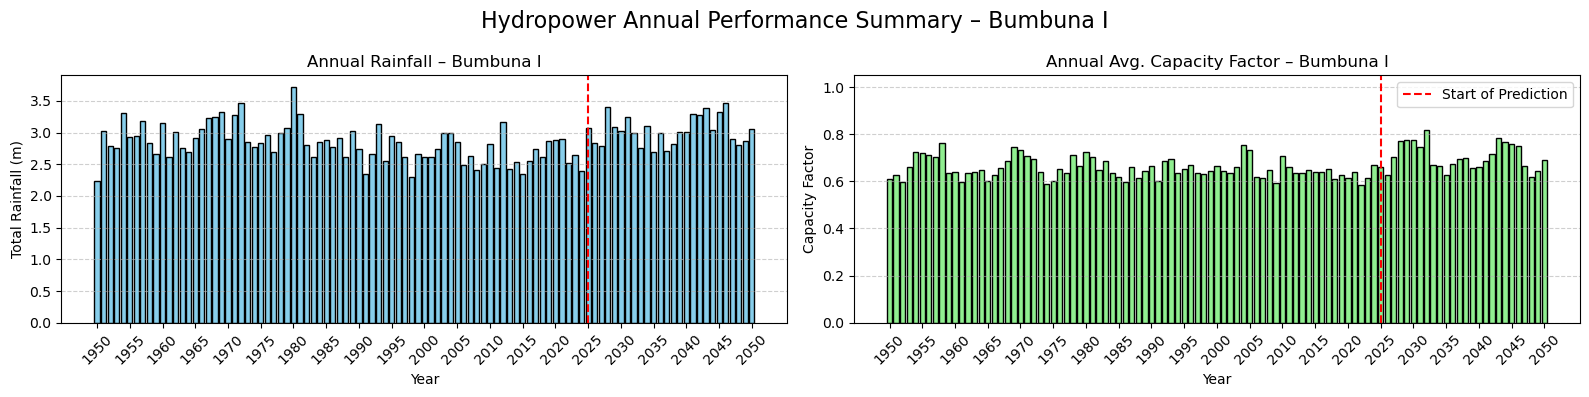

In [4]:
import matplotlib.pyplot as plt
import numpy as np

# === User Input ===
selected_plant = "Bumbuna I"

# === Data extraction ===
df = rainfall_data[selected_plant]
annual_rainfall = df["Rainfall_m"].resample("Y").sum()
annual_cf = df["Capacity_Factor"].resample("Y").mean()
years = annual_rainfall.index.year

# Determine tick positions: every 5 years
tick_step = 5
tick_years = years[::tick_step]

# Year to mark as prediction start
prediction_year = 2025

# === Plot ===
fig, axes = plt.subplots(1, 2, figsize=(16, 4), sharex=False)

# Plot 1: Annual Rainfall
axes[0].bar(years, annual_rainfall.values, color="skyblue", edgecolor="black")
axes[0].set_title(f"Annual Rainfall – {selected_plant}")
axes[0].set_ylabel("Total Rainfall (m)")
axes[0].set_xlabel("Year")
axes[0].set_xticks(tick_years)
axes[0].set_xticklabels(tick_years, rotation=45)
axes[0].axvline(x=prediction_year, color="red", linestyle="--", linewidth=1.5, label="Start of Prediction")
axes[0].grid(axis="y", linestyle="--", alpha=0.6)

# Plot 2: Annual Avg Capacity Factor
axes[1].bar(years, annual_cf.values, color="lightgreen", edgecolor="black")
axes[1].set_title(f"Annual Avg. Capacity Factor – {selected_plant}")
axes[1].set_ylabel("Capacity Factor")
axes[1].set_xlabel("Year")
axes[1].set_ylim(0, 1.05)
axes[1].set_xticks(tick_years)
axes[1].set_xticklabels(tick_years, rotation=45)
axes[1].axvline(x=prediction_year, color="red", linestyle="--", linewidth=1.5, label="Start of Prediction")
axes[1].legend()
axes[1].grid(axis="y", linestyle="--", alpha=0.6)

plt.suptitle(f"Hydropower Annual Performance Summary – {selected_plant}", fontsize=16)
plt.tight_layout()
plt.show()


### Monthly Average Capacity Factor per Plant

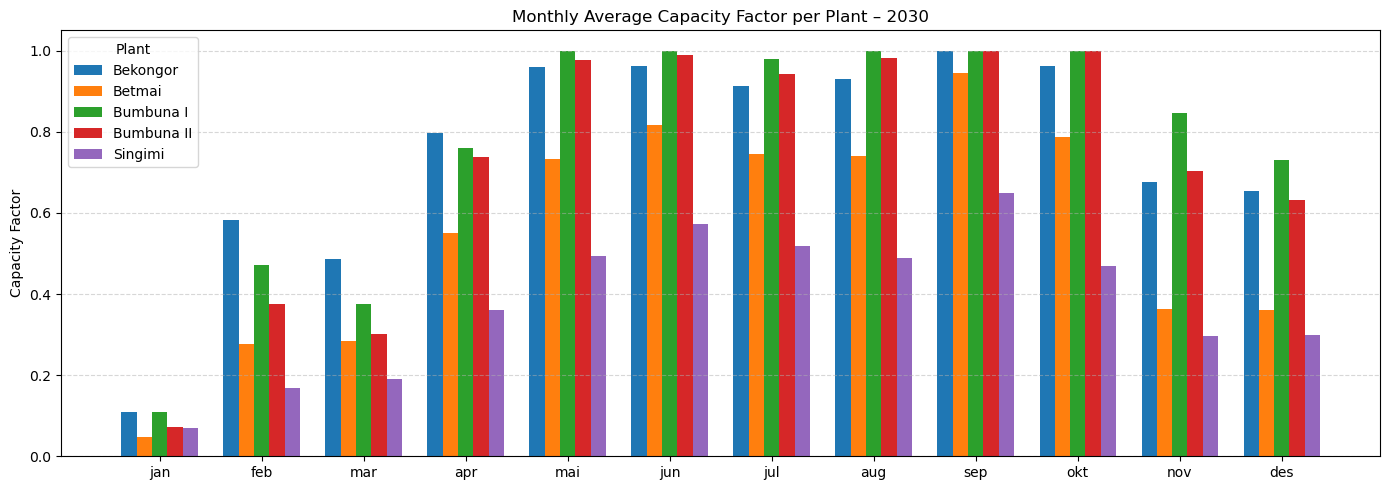

In [5]:
import calendar
import matplotlib.pyplot as plt
import pandas as pd

# === User Input ===
selected_year = 2030  # Change this to any year (e.g., 2025, 2035)

# Prepare a list of plants and a dataframe to collect monthly CFs
plants = list(rainfall_data.keys())
monthly_cf_data = pd.DataFrame(index=range(1, 13), columns=plants)  # Index = months 1–12

# Calculate average monthly CF for each plant in the selected year
for plant in plants:
    df = rainfall_data[plant]
    year_df = df[df.index.year == selected_year]
    if not year_df.empty:
        monthly_avg = year_df.groupby(year_df.index.month)["Capacity_Factor"].mean()
        monthly_cf_data[plant] = monthly_avg

# Plot: Monthly Capacity Factor Comparison
fig, ax = plt.subplots(figsize=(14, 5))

# Plot grouped bars per month
bar_width = 0.15
months = monthly_cf_data.index
x = range(len(months))

for i, plant in enumerate(plants):
    offset = (i - 2) * bar_width  # Center the groups
    ax.bar(
        [m + offset for m in x],
        monthly_cf_data[plant],
        width=bar_width,
        label=plant
    )

ax.set_xticks(x)
ax.set_xticklabels([calendar.month_abbr[m] for m in months])
ax.set_ylabel("Capacity Factor")
ax.set_title(f"Monthly Average Capacity Factor per Plant – {selected_year}")
ax.set_ylim(0, 1.05)
ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.legend(title="Plant")
plt.tight_layout()
plt.show()


### Average Annual Capacity Factor Trend by Plant

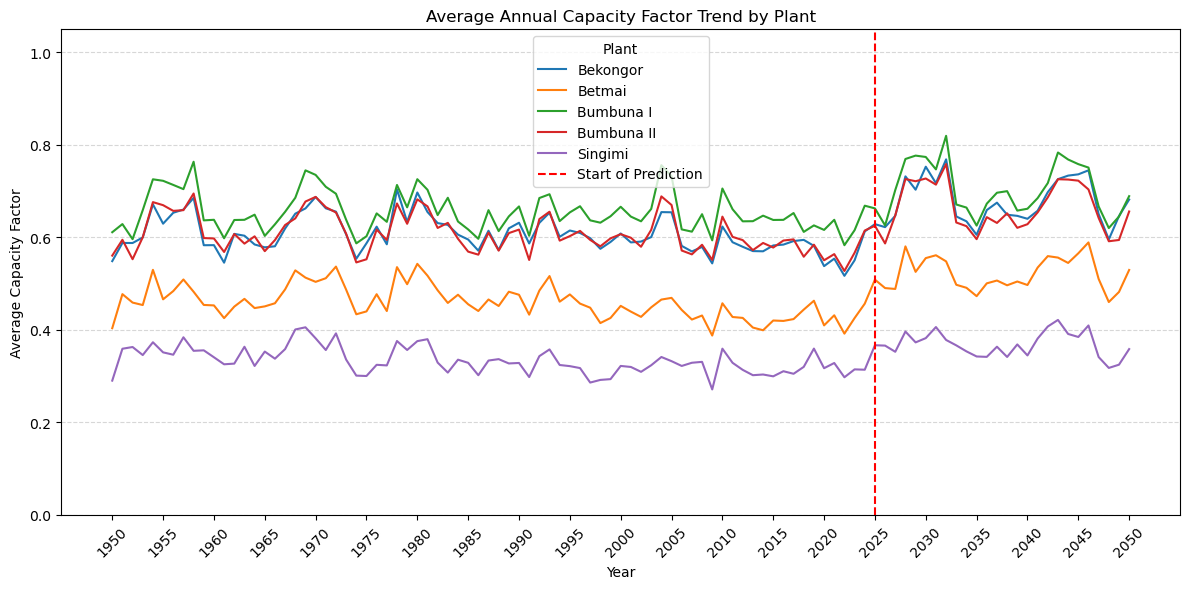

In [6]:
import matplotlib.pyplot as plt
import pandas as pd

# === Prepare data for all plants ===
plant_names = list(rainfall_data.keys())
cf_by_year = {}

# Collect annual average CF per plant
for plant in plant_names:
    df = rainfall_data[plant].copy()
    df["Year"] = df.index.year
    annual_cf = df.groupby("Year")["Capacity_Factor"].mean()
    cf_by_year[plant] = annual_cf

# Create a common year index (union of all years from all plants)
all_years = sorted(set(int(year) for series in cf_by_year.values() for year in series.index))


# === Plotting ===
fig, ax = plt.subplots(figsize=(12, 6))

# Plot a line for each plant
for plant in plant_names:
    annual_cf = cf_by_year[plant]
    annual_cf = annual_cf.reindex(all_years, fill_value=0)  # Fill missing years with 0
    ax.plot(all_years, annual_cf.values, label=plant)

# Red dashed line at 2025
ax.axvline(x=2025, color="red", linestyle="--", linewidth=1.5, label="Start of Prediction")

# Axis formatting
ax.set_title("Average Annual Capacity Factor Trend by Plant")
ax.set_xlabel("Year")
ax.set_ylabel("Average Capacity Factor")
ax.set_ylim(0, 1.05)
ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.legend(title="Plant")

# Set x-axis ticks every 5 years
tick_years = list(range(min(all_years), max(all_years)+1, 5))
ax.set_xticks(tick_years)
ax.set_xticklabels([str(y) for y in tick_years], rotation=45)

plt.tight_layout()
plt.show()


## Seasonal Capacity Factor Comparison by Plant

This plot visualizes the average **capacity factor** of each hydropower plant in a user-selected year, 
**broken down by season**:

- **Dry Season**: November to April  
- **Wet Season**: May to October  

Each plant is represented by a **stacked bar**, where:
- The bottom segment shows the average capacity factor during the dry season.
- The top segment shows the average during the wet season.

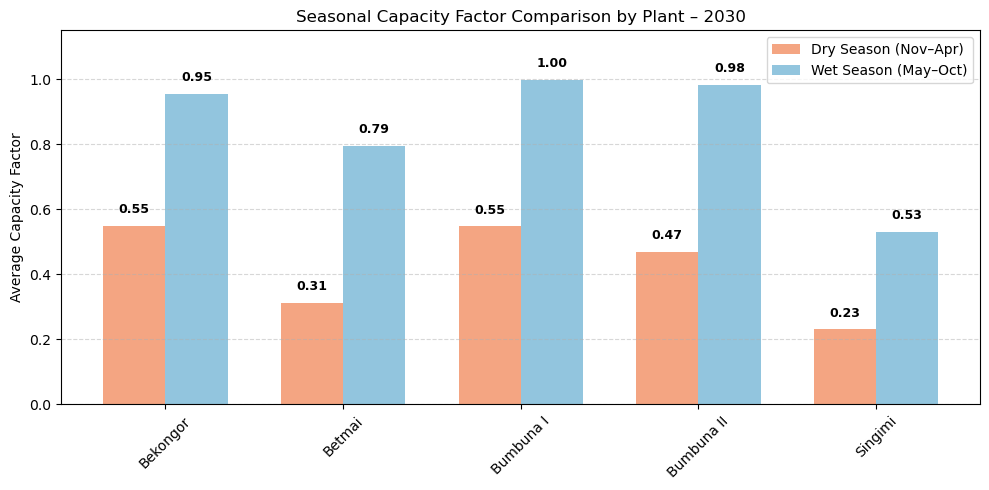

In [7]:
import matplotlib.pyplot as plt
import numpy as np

# === User Input ===
selected_year = 2030

# Define season months
dry_months = [11, 12, 1, 2, 3, 4]
wet_months = [5, 6, 7, 8, 9, 10]

# Prepare data
plants = list(rainfall_data.keys())
dry_cf = []
wet_cf = []

for plant in plants:
    df = rainfall_data[plant]
    year_df = df[df.index.year == selected_year]

    dry_avg = year_df[year_df.index.month.isin(dry_months)]["Capacity_Factor"].mean()
    wet_avg = year_df[year_df.index.month.isin(wet_months)]["Capacity_Factor"].mean()

    dry_cf.append(dry_avg if not pd.isna(dry_avg) else 0)
    wet_cf.append(wet_avg if not pd.isna(wet_avg) else 0)

# === Plotting grouped bars ===
x = np.arange(len(plants))
bar_width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))

bars_dry = ax.bar(x - bar_width/2, dry_cf, width=bar_width, color="#f4a582", label="Dry Season (Nov–Apr)")
bars_wet = ax.bar(x + bar_width/2, wet_cf, width=bar_width, color="#92c5de", label="Wet Season (May–Oct)")

# Axis and title formatting
ax.set_xticks(x)
ax.set_xticklabels(plants, rotation=45)
ax.set_ylabel("Average Capacity Factor")
ax.set_title(f"Seasonal Capacity Factor Comparison by Plant – {selected_year}")
ax.set_ylim(0, 1.15)  # Increased headroom for labels
ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.legend()

# Add rounded value labels
def add_labels(bars):
    for bar in bars:
        height = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width()/2,
            height + 0.03,  # More spacing above the bar
            f"{height:.2f}",
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="bold"
        )

add_labels(bars_dry)
add_labels(bars_wet)

plt.tight_layout()
plt.show()


### Trend of Seasonal Capacity Factor over the years

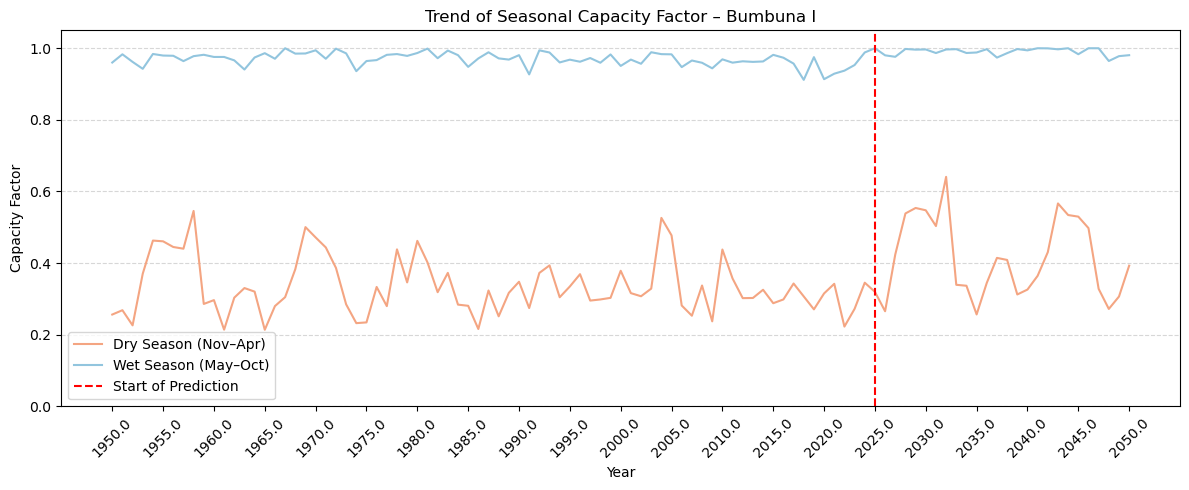

In [8]:
import matplotlib.pyplot as plt
import pandas as pd

# === User Input ===
selected_plant = "Bumbuna I"  # Change this to any plant name

# Define dry and wet season months
dry_months = [11, 12, 1, 2, 3, 4]
wet_months = [5, 6, 7, 8, 9, 10]

# Prepare DataFrame to store seasonal averages by year
df = rainfall_data[selected_plant]
years = df.index.year.unique()
dry_cf_trend = []
wet_cf_trend = []

for year in sorted(years):
    yearly_df = df[df.index.year == year]
    
    # Extract dry/wet season months
    dry_cf = yearly_df[yearly_df.index.month.isin(dry_months)]["Capacity_Factor"].mean()
    wet_cf = yearly_df[yearly_df.index.month.isin(wet_months)]["Capacity_Factor"].mean()
    
    dry_cf_trend.append(dry_cf if not pd.isna(dry_cf) else 0)
    wet_cf_trend.append(wet_cf if not pd.isna(wet_cf) else 0)

# Create a plot
fig, ax = plt.subplots(figsize=(12, 5))

# Plot lines
ax.plot(sorted(years), dry_cf_trend, color="#f4a582", label="Dry Season (Nov–Apr)")
ax.plot(sorted(years), wet_cf_trend, color="#92c5de", label="Wet Season (May–Oct)")

# Vertical line for prediction boundary
ax.axvline(x=2025, color="red", linestyle="--", linewidth=1.5, label="Start of Prediction")

# Formatting
ax.set_title(f"Trend of Seasonal Capacity Factor – {selected_plant}")
ax.set_xlabel("Year")
ax.set_ylabel("Capacity Factor")
ax.set_ylim(0, 1.05)
ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.legend()

# Show every 5th year on x-axis
tick_years = sorted(years)[::5]
ax.set_xticks(tick_years)
ax.set_xticklabels(tick_years, rotation=45)

plt.tight_layout()
plt.show()


### Monthly Capacity Factors - Table View

In [9]:
# Create dictionary to store all monthly capacity factor tables
monthly_cf_tables = {}

# Loop through all plants and compute the pivot table
for plant in rainfall_data:
    df = rainfall_data[plant].copy()
    df["Year"] = df.index.year
    df["Month"] = df.index.month

    # Group by Month and Year, compute average CF, then pivot
    monthly_cf = df.groupby(["Month", "Year"])["Capacity_Factor"].mean().unstack()

    # Store the result
    monthly_cf_tables[plant] = monthly_cf

In [10]:
from IPython.display import display

# Loop through plants and show filtered tables from 2025 onward
for plant, table in monthly_cf_tables.items():
    # Keep only columns for years ≥ 2025
    future_table = table.loc[:, table.columns >= 2025]

    # Skip if table is empty (no data for 2025+)
    if future_table.empty:
        continue

    # Optional: format month numbers to names
    future_table.index = future_table.index.astype(int).map(lambda m: calendar.month_abbr[m])

    print(f"\n📊 {plant} – Monthly Capacity Factor (2025 onward)")
    display(future_table.round(3))



📊 Bekongor – Monthly Capacity Factor (2025 onward)


Year,2025.0,2026.0,2027.0,2028.0,2029.0,2030.0,2031.0,2032.0,2033.0,2034.0,...,2041.0,2042.0,2043.0,2044.0,2045.0,2046.0,2047.0,2048.0,2049.0,2050.0
Month,,,,,,,,,,,,,,,,,,,,,
jan,0.090,0.030,0.161,0.196,0.079,0.108,0.092,0.348,0.121,0.071,...,0.014,0.162,0.174,0.180,0.049,0.370,0.012,0.008,0.051,0.225
feb,0.054,0.133,0.116,0.231,0.343,0.582,0.123,0.538,0.120,0.153,...,0.008,0.178,0.236,0.390,0.330,0.402,0.036,0.034,0.053,0.073
mar,0.197,0.276,0.292,0.556,0.814,0.487,0.522,0.608,0.184,0.249,...,0.170,0.244,0.675,0.426,0.261,0.624,0.311,0.186,0.200,0.413
apr,0.591,0.449,0.581,0.858,0.827,0.796,0.756,0.806,0.662,0.444,...,0.785,0.556,0.839,0.885,0.916,0.866,0.681,0.306,0.729,0.785
mai,0.934,0.917,0.927,0.931,0.960,0.960,0.955,0.911,0.993,0.881,...,0.978,0.991,0.889,0.988,0.924,0.994,0.964,0.753,0.908,0.941
jun,0.988,1.000,0.928,0.993,0.980,0.962,0.982,0.982,0.922,0.994,...,0.996,0.968,0.976,0.956,0.991,0.992,0.986,0.947,0.984,0.981
jul,0.972,0.941,0.933,0.951,0.923,0.913,0.961,0.950,0.992,0.904,...,0.977,1.000,0.988,0.984,0.989,0.990,0.995,0.964,0.950,0.989
aug,1.000,0.971,0.964,0.970,0.917,0.930,0.949,0.913,0.902,0.986,...,0.959,0.996,0.982,0.992,0.920,0.988,0.996,0.960,0.979,0.958
sep,1.000,1.000,0.941,1.000,0.994,1.000,1.000,0.993,0.986,1.000,...,0.992,0.972,0.977,0.969,1.000,0.984,0.995,0.974,0.995,1.000



📊 Betmai – Monthly Capacity Factor (2025 onward)


Year,2025.0,2026.0,2027.0,2028.0,2029.0,2030.0,2031.0,2032.0,2033.0,2034.0,...,2041.0,2042.0,2043.0,2044.0,2045.0,2046.0,2047.0,2048.0,2049.0,2050.0
Month,,,,,,,,,,,,,,,,,,,,,
jan,0.033,0.014,0.068,0.101,0.034,0.048,0.038,0.184,0.047,0.022,...,0.003,0.058,0.081,0.072,0.020,0.179,0.004,0.003,0.018,0.101
feb,0.024,0.047,0.042,0.137,0.195,0.276,0.057,0.230,0.056,0.068,...,0.002,0.080,0.104,0.207,0.200,0.161,0.016,0.008,0.020,0.027
mar,0.088,0.147,0.195,0.328,0.469,0.285,0.283,0.385,0.080,0.116,...,0.051,0.103,0.432,0.264,0.118,0.371,0.173,0.059,0.097,0.228
apr,0.304,0.250,0.351,0.622,0.563,0.550,0.535,0.512,0.421,0.233,...,0.589,0.395,0.497,0.617,0.553,0.567,0.508,0.186,0.429,0.544
mai,0.817,0.664,0.759,0.748,0.795,0.734,0.780,0.686,0.808,0.683,...,0.871,0.817,0.602,0.823,0.734,0.933,0.787,0.566,0.706,0.731
jun,0.786,0.914,0.782,0.858,0.829,0.817,0.786,0.754,0.734,0.886,...,0.888,0.867,0.844,0.685,0.792,0.885,0.818,0.787,0.850,0.839
jul,0.850,0.803,0.778,0.710,0.799,0.744,0.790,0.671,0.926,0.736,...,0.882,0.931,0.867,0.785,0.874,0.864,0.903,0.861,0.749,0.790
aug,0.933,0.829,0.717,0.829,0.690,0.741,0.831,0.664,0.728,0.892,...,0.822,0.914,0.848,0.818,0.749,0.849,0.875,0.810,0.790,0.793
sep,0.873,0.955,0.831,0.960,0.856,0.944,0.936,0.856,0.909,0.927,...,0.956,0.874,0.906,0.882,0.912,0.903,0.888,0.858,0.916,0.885



📊 Bumbuna I – Monthly Capacity Factor (2025 onward)


Year,2025.0,2026.0,2027.0,2028.0,2029.0,2030.0,2031.0,2032.0,2033.0,2034.0,...,2041.0,2042.0,2043.0,2044.0,2045.0,2046.0,2047.0,2048.0,2049.0,2050.0
Month,,,,,,,,,,,,,,,,,,,,,
jan,0.100,0.023,0.353,0.247,0.126,0.108,0.084,0.475,0.156,0.057,...,0.027,0.133,0.246,0.257,0.086,0.290,0.012,0.007,0.059,0.270
feb,0.058,0.071,0.115,0.230,0.384,0.472,0.133,0.525,0.093,0.105,...,0.010,0.215,0.143,0.351,0.306,0.356,0.030,0.014,0.030,0.047
mar,0.197,0.247,0.311,0.506,0.788,0.376,0.562,0.604,0.107,0.222,...,0.121,0.160,0.828,0.423,0.155,0.609,0.204,0.138,0.109,0.426
apr,0.714,0.327,0.578,0.970,0.958,0.761,0.728,0.841,0.627,0.467,...,0.749,0.595,0.913,0.941,0.935,0.881,0.741,0.322,0.557,0.718
mai,1.000,0.891,0.914,0.988,1.000,1.000,0.921,1.000,1.000,0.979,...,1.000,0.998,0.982,1.000,0.905,1.000,1.000,0.789,0.870,0.885
jun,1.000,1.000,0.980,1.000,0.999,1.000,1.000,1.000,1.000,1.000,...,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
jul,1.000,0.992,0.966,1.000,0.986,0.980,1.000,0.983,1.000,0.942,...,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,0.999,1.000
aug,1.000,1.000,1.000,1.000,0.992,1.000,1.000,0.996,0.984,1.000,...,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
sep,1.000,1.000,0.997,1.000,1.000,1.000,1.000,1.000,1.000,1.000,...,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000



📊 Bumbuna II – Monthly Capacity Factor (2025 onward)


Year,2025.0,2026.0,2027.0,2028.0,2029.0,2030.0,2031.0,2032.0,2033.0,2034.0,...,2041.0,2042.0,2043.0,2044.0,2045.0,2046.0,2047.0,2048.0,2049.0,2050.0
Month,,,,,,,,,,,,,,,,,,,,,
jan,0.076,0.013,0.212,0.152,0.057,0.073,0.054,0.322,0.108,0.045,...,0.025,0.103,0.137,0.153,0.040,0.202,0.010,0.007,0.035,0.177
feb,0.021,0.038,0.091,0.151,0.253,0.376,0.112,0.389,0.060,0.071,...,0.002,0.166,0.103,0.249,0.227,0.230,0.014,0.006,0.018,0.024
mar,0.153,0.175,0.251,0.380,0.734,0.302,0.505,0.521,0.084,0.183,...,0.074,0.107,0.694,0.292,0.119,0.534,0.157,0.108,0.067,0.370
apr,0.538,0.285,0.441,0.878,0.824,0.737,0.672,0.754,0.532,0.359,...,0.645,0.498,0.745,0.872,0.871,0.771,0.683,0.270,0.417,0.676
mai,0.977,0.827,0.879,0.971,1.000,0.977,0.869,0.960,1.000,0.942,...,1.000,0.977,0.908,1.000,0.894,1.000,1.000,0.783,0.830,0.861
jun,0.993,1.000,0.926,1.000,0.983,0.990,1.000,1.000,0.971,1.000,...,1.000,0.984,1.000,0.990,1.000,1.000,0.986,0.997,1.000,0.992
jul,1.000,0.980,0.964,0.978,0.952,0.943,0.999,0.941,1.000,0.927,...,0.990,0.994,1.000,1.000,1.000,1.000,0.999,1.000,0.968,1.000
aug,1.000,1.000,0.996,1.000,0.983,0.981,0.965,0.965,0.924,1.000,...,1.000,1.000,1.000,1.000,0.990,1.000,1.000,0.998,0.981,0.997
sep,1.000,1.000,0.984,1.000,1.000,1.000,1.000,0.995,0.999,1.000,...,1.000,0.995,1.000,1.000,1.000,0.991,0.989,1.000,1.000,1.000



📊 Singimi – Monthly Capacity Factor (2025 onward)


Year,2025.0,2026.0,2027.0,2028.0,2029.0,2030.0,2031.0,2032.0,2033.0,2034.0,...,2041.0,2042.0,2043.0,2044.0,2045.0,2046.0,2047.0,2048.0,2049.0,2050.0
Month,,,,,,,,,,,,,,,,,,,,,
jan,0.066,0.036,0.092,0.134,0.059,0.070,0.084,0.177,0.079,0.043,...,0.010,0.099,0.071,0.100,0.049,0.149,0.016,0.011,0.043,0.089
feb,0.044,0.032,0.071,0.073,0.135,0.169,0.071,0.200,0.076,0.097,...,0.013,0.057,0.046,0.148,0.116,0.124,0.024,0.023,0.042,0.035
mar,0.044,0.112,0.128,0.165,0.292,0.190,0.186,0.307,0.072,0.095,...,0.027,0.079,0.315,0.145,0.041,0.230,0.072,0.032,0.039,0.095
apr,0.161,0.157,0.239,0.386,0.345,0.361,0.301,0.402,0.259,0.167,...,0.322,0.161,0.373,0.455,0.235,0.352,0.312,0.072,0.147,0.318
mai,0.501,0.472,0.498,0.532,0.492,0.494,0.532,0.460,0.471,0.484,...,0.575,0.592,0.377,0.570,0.468,0.683,0.474,0.257,0.354,0.473
jun,0.505,0.653,0.618,0.547,0.647,0.572,0.533,0.510,0.487,0.567,...,0.610,0.605,0.624,0.393,0.539,0.666,0.529,0.490,0.532,0.626
jul,0.679,0.612,0.611,0.526,0.602,0.517,0.642,0.363,0.709,0.562,...,0.597,0.695,0.729,0.601,0.634,0.585,0.630,0.689,0.526,0.536
aug,0.699,0.688,0.570,0.669,0.531,0.488,0.608,0.455,0.589,0.634,...,0.710,0.772,0.674,0.652,0.600,0.618,0.634,0.599,0.551,0.550
sep,0.650,0.799,0.546,0.679,0.603,0.650,0.680,0.620,0.697,0.713,...,0.775,0.609,0.666,0.678,0.708,0.610,0.604,0.599,0.762,0.558


### Export Results for OSeMOSYS

In [11]:
import os
import pandas as pd

# Output directory
output_dir = "capacity factor data/results"
os.makedirs(output_dir, exist_ok=True)

# Function to build time slice index with D/N
def build_timeslice_rows(months_index):
    rows = []
    for month in months_index:  
        month_code = f"M{int(month):02d}"
        for suffix in ["D", "N"]:
            rows.append(f"{month_code}{suffix}")
    return rows

# Export for each plant
for plant, table in monthly_cf_tables.items():
    # Filter to years ≥ 2025
    future_table = table.loc[:, table.columns >= 2025]

    # Skip if empty
    if future_table.empty:
        continue

    # Duplicate rows: one for Day (D), one for Night (N)
    duplicated = pd.DataFrame(index=build_timeslice_rows(future_table.index), columns=future_table.columns)

    for month in future_table.index:
        month_code = f"M{int(month):02d}"
        value_row = future_table.loc[month]
        duplicated.loc[f"{month_code}D"] = value_row
        duplicated.loc[f"{month_code}N"] = value_row

    # Round values and ensure float format with dot decimal
    duplicated = duplicated.astype(float).round(3)

    # Save to Excel
    safe_plant_name = plant.replace(" ", "_")
    output_path = os.path.join(output_dir, f"{safe_plant_name}.xlsx")
    duplicated.to_excel(output_path, sheet_name="Monthly_CF", float_format="%.3f")

    print(f"✅ Excel file saved: {output_path}")


✅ Excel file saved: capacity factor data/results\Bekongor.xlsx
✅ Excel file saved: capacity factor data/results\Betmai.xlsx
✅ Excel file saved: capacity factor data/results\Bumbuna_I.xlsx
✅ Excel file saved: capacity factor data/results\Bumbuna_II.xlsx
✅ Excel file saved: capacity factor data/results\Singimi.xlsx


## Categorize Hydropower Plants by Average Capacity Factor

In [13]:
import pandas as pd

# Constants for categories
HIGH_CF_THRESHOLD = 0.60
MEDIUM_CF_THRESHOLD = 0.40

# Helper: Build day/night time slice index
def build_timeslice_rows(months_index):
    rows = []
    for month in months_index:
        month_code = f"M{int(month):02d}"
        for suffix in ["D", "N"]:
            rows.append(f"{month_code}{suffix}")
    return rows

# Prepare dictionaries
category_data = {
    "High": [],
    "Medium": [],
    "Low": []
}
category_cf_summary = {}

# Categorize plants and compute average monthly CF
for plant, df in rainfall_data.items():
    df = df.copy()
    df["Year"] = df.index.year
    df["Month"] = df.index.month

    # Annual and long-term average
    annual_cf = df.groupby("Year")["Capacity_Factor"].mean()
    long_term_avg = annual_cf.mean()

    if long_term_avg >= HIGH_CF_THRESHOLD:
        category = "High"
    elif long_term_avg >= MEDIUM_CF_THRESHOLD:
        category = "Medium"
    else:
        category = "Low"

    # Save average CF summary
    category_cf_summary[plant] = {"Category": category, "Avg_CF": round(long_term_avg, 3)}

    # Monthly average CF
    monthly_cf = df.groupby("Month")["Capacity_Factor"].mean()
    duplicated = pd.DataFrame(index=build_timeslice_rows(monthly_cf.index), columns=[plant])

    for month in monthly_cf.index:
        month_code = f"M{int(month):02d}"
        value = monthly_cf.loc[month]
        duplicated.loc[f"{month_code}D"] = value
        duplicated.loc[f"{month_code}N"] = value

    category_data[category].append(duplicated)

# Convert summary to DataFrame
summary_df = pd.DataFrame.from_dict(category_cf_summary, orient="index")
display(summary_df)

# Print the tables
for cat, df_list in category_data.items():
    print(f"\n📊 {cat} Capacity Factor Category:")
    if df_list:
        display(pd.concat(df_list, axis=1).round(3))
    else:
        print("No plants in this category.")

,Category,Avg_CF
Bekongor,High,0.624
Betmai,Medium,0.475
Bumbuna I,High,0.667
Bumbuna II,High,0.621
Singimi,Low,0.342



📊 High Capacity Factor Category:


,Bekongor,Bumbuna I,Bumbuna II
M01D,0.09278,0.109663,0.076227
M01N,0.09278,0.109663,0.076227
M02D,0.140491,0.129738,0.091659
M02N,0.140491,0.129738,0.091659
M03D,0.31287,0.296962,0.235492
M03N,0.31287,0.296962,0.235492
M04D,0.598079,0.613561,0.513289
M04N,0.598079,0.613561,0.513289
M05D,0.853522,0.914573,0.859551
M05N,0.853522,0.914573,0.859551



📊 Medium Capacity Factor Category:


,Betmai
M01D,0.045618
M01N,0.045618
M02D,0.070866
M02N,0.070866
M03D,0.177925
M03N,0.177925
M04D,0.387425
M04N,0.387425
M05D,0.671455
M05N,0.671455



📊 Low Capacity Factor Category:


,Singimi
M01D,0.054751
M01N,0.054751
M02D,0.059554
M02N,0.059554
M03D,0.111833
M03N,0.111833
M04D,0.238701
M04N,0.238701
M05D,0.456158
M05N,0.456158


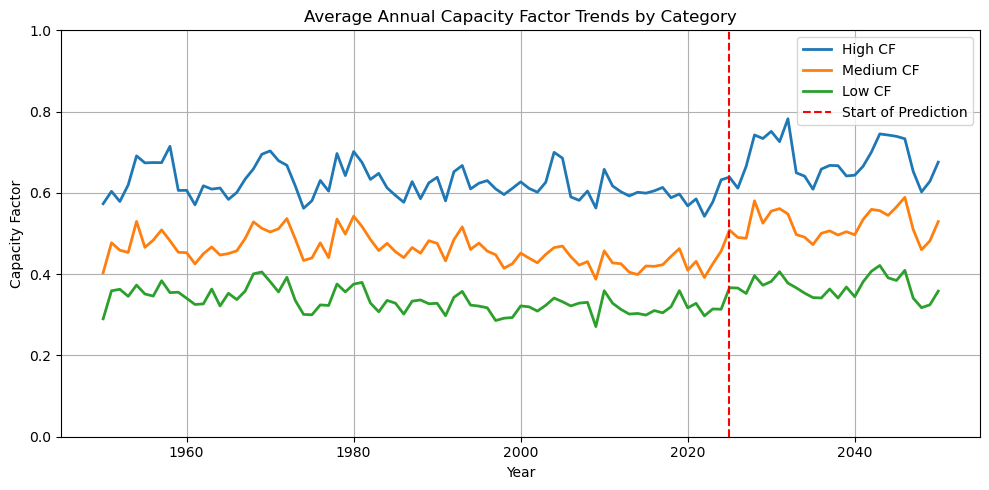

In [14]:
import matplotlib.pyplot as plt

# Build per-category annual trend DataFrame
category_annual_cf = {"High": [], "Medium": [], "Low": []}

for plant, df in rainfall_data.items():
    annual_cf = df["Capacity_Factor"].resample("Y").mean()
    year_series = annual_cf.index.year

    cat = category_cf_summary[plant]["Category"]
    category_annual_cf[cat].append(pd.Series(annual_cf.values, index=year_series))

# Aggregate and average across all plants in each category
mean_trends = {}
for cat, series_list in category_annual_cf.items():
    if series_list:
        df = pd.concat(series_list, axis=1)
        mean_trends[cat] = df.mean(axis=1)

# Plot
plt.figure(figsize=(10, 5))
for cat, series in mean_trends.items():
    plt.plot(series.index, series.values, label=f"{cat} CF", linewidth=2)

plt.axvline(x=2025, color='r', linestyle='--', label="Start of Prediction")
plt.title("Average Annual Capacity Factor Trends by Category")
plt.ylabel("Capacity Factor")
plt.xlabel("Year")
plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [16]:
import calendar
import openpyxl

# Output directory
output_dir = "capacity factor data/results_by_category_excel"
os.makedirs(output_dir, exist_ok=True)

def build_timeslice_rows(months_index):
    rows = []
    for month in months_index:
        month_code = f"M{int(month):02d}"
        for suffix in ["D", "N"]:
            rows.append(f"{month_code}{suffix}")
    return rows

# Build new Excel output for each category
for category in ["High", "Medium", "Low"]:
    plants_in_category = [p for p, meta in category_cf_summary.items() if meta["Category"] == category]
    
    if not plants_in_category:
        continue

    # Collect per-plant future monthly CF tables
    plant_tables = []
    for plant in plants_in_category:
        table = monthly_cf_tables[plant]
        future_table = table.loc[:, table.columns >= 2025]

        if future_table.empty:
            continue

        # Duplicate for Day and Night timeslices
        duplicated = pd.DataFrame(index=build_timeslice_rows(future_table.index), columns=future_table.columns)

        for month in future_table.index:
            month_code = f"M{int(month):02d}"
            row_values = future_table.loc[month]
            duplicated.loc[f"{month_code}D"] = row_values
            duplicated.loc[f"{month_code}N"] = row_values

        # Rename columns to keep track of the plant
        duplicated.name = plant
        plant_tables.append(duplicated)

    # Average across all plants in category
    if plant_tables:
        combined = sum(plant_tables) / len(plant_tables)
        combined = combined.astype(float).round(3)
        combined.index.name = "TimeSlice"

        # Export to Excel
        output_path = os.path.join(output_dir, f"{category}_CapacityFactor.xlsx")
        combined.to_excel(output_path, sheet_name="Monthly_CF_By_Year")
        print(f"✅ Excel file saved: {output_path}")

✅ Excel file saved: capacity factor data/results_by_category_excel\High_CapacityFactor.xlsx
✅ Excel file saved: capacity factor data/results_by_category_excel\Medium_CapacityFactor.xlsx
✅ Excel file saved: capacity factor data/results_by_category_excel\Low_CapacityFactor.xlsx
